# What Batman plots are made of

Complete summaries cover **59 of 69** ranked 1980s stories, but only **8 of 69** from the 2020s. The words lean toward older comics.

Series, formats and wiki plot summaries, with **rank 1 best**.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
COLORS = {"blue": "#2767A0", "orange": "#D57927", "green": "#26806B", "grey": "#75818C"}
pd.set_option("display.max_rows", 20)
pd.set_option("display.min_rows", 10)
pd.set_option("styler.render.max_rows", 20)

sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
pd.set_option("display.max_colwidth", 70)


def rank_summary(frame, by):
    """Count, median rank, and best/worst-ranked story titles per group."""
    return (
        frame.sort_values("rank")
        .groupby(by)
        .agg(
            n=("story_id", "nunique"),
            median_rank=("rank", "median"),
            best_rank=("rank", "first"),
            best_story=("title", "first"),
            worst_rank=("rank", "last"),
            worst_story=("title", "last"),
        )
    )


def rank_boxes(ax, entries, key, labels, color=COLORS["blue"]):
    """Box of the middle half plus one faint dot per story, in the order of `labels`."""
    chart = entries[entries[key].isin(labels.index)].assign(label=lambda d: d[key].map(labels))
    common = dict(data=chart, x="rank", y="label", order=labels.tolist(), ax=ax)
    sns.stripplot(**common, color=COLORS["grey"], alpha=0.35, size=3, jitter=False, zorder=0)
    sns.boxplot(**common, color=color, whis=0, showfliers=False, width=0.45)
    ax.set(xlabel="BatChat rank · 1 = best", ylabel="", xlim=(1, N))


PRETTY = {
    "n": "Stories",
    "median_rank": "Median rank",
    "best_rank": "Best rank",
    "best_story": "Best-ranked story",
    "worst_rank": "Worst rank",
    "worst_story": "Worst-ranked story",
}


def collapsible(summary, table, note="", **to_html):
    """Show at most 20 rows, preserving both ends of longer sorted tables."""
    total = len(table)
    if total > 20:
        table = pd.concat([table.head(10), table.tail(10)])
        note = f"{note} Showing the first 10 and last 10 of {total:,} rows; middle rows omitted."
    body = table.to_html(escape=True, **to_html)
    return HTML(f"<details><summary>{summary}</summary><p>{note}</p>{body}</details>")


stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
texts = pd.read_csv(DATA / "story_texts.csv")
N = len(stories)
print(f"{N:,} ranked stories · {len(issues):,} issues")

740 ranked stories · 2,434 issues


## Which series fare best?

The twelve most represented series. Relaunch volumes are combined; each story counts once per series. Cross-series readings appear in each relevant row. Among these twelve, *Batman Adventures* has the best median rank (**261**); *The Brave and the Bold* has the lowest placement (**510**). These groupings describe titles rather than individual creative runs.

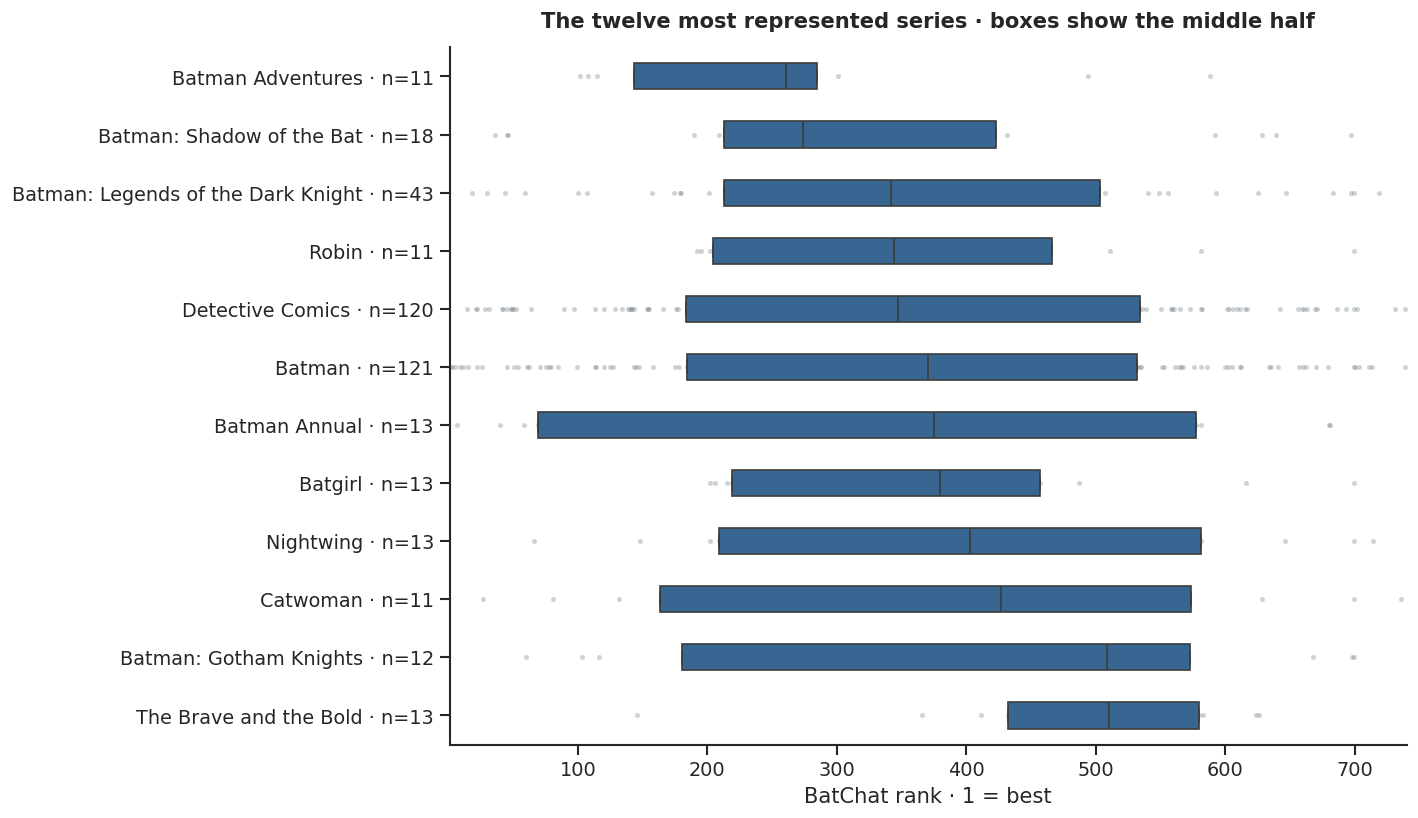

669 of 740 stories have a matched series title.


,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Series,,,,,,
Gotham Central,6,73.5,12,Soft Targets,194,Nature
Batman Incorporated,4,80.0,25,Leviathan Strikes,474,No More Teachers
Batman: Legends of the Dark Knight Halloween Special,3,164.0,144,Choices/Fears,299,Ghosts
JLA,6,165.0,43,Tower of Babel,604,Bouncing Baby Boy
Batman '66,4,166.0,126,Batman ’66 V.1,223,Batman ’66 V.3
Batman Chronicles,4,182.5,117,Oracle: Year One- Born of Hope,365,Batman Chronicles #11
Batman Eternal,3,184.0,77,Batman: Eternal Part 1,243,Batman: Eternal V.2
Batman and Robin,9,197.0,47,Undone,227,Little Big Man
Birds of Prey,6,222.5,122,On Wings,511,Officer Down


In [2]:
series_links = issues[["story_id", "wiki_title"]].dropna().copy()
series_links["Series"] = series_links.wiki_title.str.extract(
    r"^(.*?) Vol \d+ \d+(?:\.\d+)?[A-Za-z]?$"
)[0]
series_links = (
    series_links.dropna(subset=["Series"])
    .drop_duplicates(["story_id", "Series"])
    .merge(stories[["story_id", "rank", "title"]], on="story_id", validate="many_to_one")
)
series_rankings = rank_summary(series_links, "Series")
top_series = series_rankings.nlargest(12, "n").sort_values("median_rank")
fig, ax = plt.subplots(figsize=(12, 7))
rank_boxes(
    ax, series_links, "Series", top_series.index.to_series() + " · n=" + top_series.n.astype(str)
)
ax.set_title("The twelve most represented series · boxes show the middle half")
fig.tight_layout()
plt.show()
print(f"{series_links.story_id.nunique()} of {N} stories have a matched series title.")

series_table = series_rankings[series_rankings.n.ge(3)].sort_values("median_rank")
display(
    collapsible(
        f"{len(series_table)} series with three or more ranked stories",
        series_table.rename(columns=PRETTY),
        "Lower median rank is better. A cross-series story can appear in several rows.",
    )
)

### Elseworlds and graphic novels

**32 stories** include an Elseworlds-labeled issue; the ranking list identifies **26** original graphic novels. These overlapping groups are plotted separately from the wiki's broader graphic-novel category, which can include collections.

*Red Rain* (#6) appears in all three groups: these are overlapping shelves. Their ranks span the list. Missing labels mean unknown, so an “ordinary comics” control group cannot be inferred.

In [3]:
labels = pd.read_csv(DATA / "story_labels.csv")
label_books = stories.merge(labels, on="story_id", validate="one_to_one")
format_groups = {
    "Elseworlds-labeled issue": label_books.elseworlds_issue_count.gt(0),
    "Original graphic novel": label_books.format_hint.eq("original_graphic_novel"),
    "Wiki graphic-novel category": label_books.graphic_novel_issue_count.gt(0),
}
format_rows = pd.concat(
    [
        label_books.loc[mask, ["story_id", "title", "rank"]].assign(label=name)
        for name, mask in format_groups.items()
    ],
    ignore_index=True,
)
display(
    rank_summary(format_rows, "label")
    .loc[list(format_groups)]
    .rename(columns=PRETTY)
    .rename_axis(None)
)
display(
    collapsible(
        "Labeled stories and their ranks",
        format_rows.sort_values(["label", "rank"])[["label", "rank", "title"]],
        index=False,
    )
)

,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Elseworlds-labeled issue,32,472.5,6,Batman/Dracula: Red Rain OGN,730,Batman: Dark Allegiances
Original graphic novel,26,352.5,6,Batman/Dracula: Red Rain OGN,721,Batman: Earth One OGN
Wiki graphic-novel category,40,467.0,6,Batman/Dracula: Red Rain OGN,730,Batman: Dark Allegiances


label,rank,title
Elseworlds-labeled issue,6,Batman/Dracula: Red Rain OGN
Elseworlds-labeled issue,8,The Dark Knight Returns
Elseworlds-labeled issue,13,Kingdom Come #1-4
Elseworlds-labeled issue,23,Batman: Crimson Mist OGN
Elseworlds-labeled issue,67,Batman: Gotham Noir
Elseworlds-labeled issue,111,Batman: Bloodstorm OGN
Elseworlds-labeled issue,130,Thrillkiller
Elseworlds-labeled issue,168,Batman: Nine Lives OGN
Elseworlds-labeled issue,214,Batman: Holy Terror
Elseworlds-labeled issue,242,Batman: Scar of the Bat


## Which stories have usable plots?

The [DC Database](https://dc.fandom.com/) supplies **1,711 summaries totaling 703,219 words**. Of the ranked stories, **587** have some text and **481** have all selected summaries plus a complete issue list.

Green means complete, orange partial, grey unavailable. The decade counts show who is missing before we analyze the words.

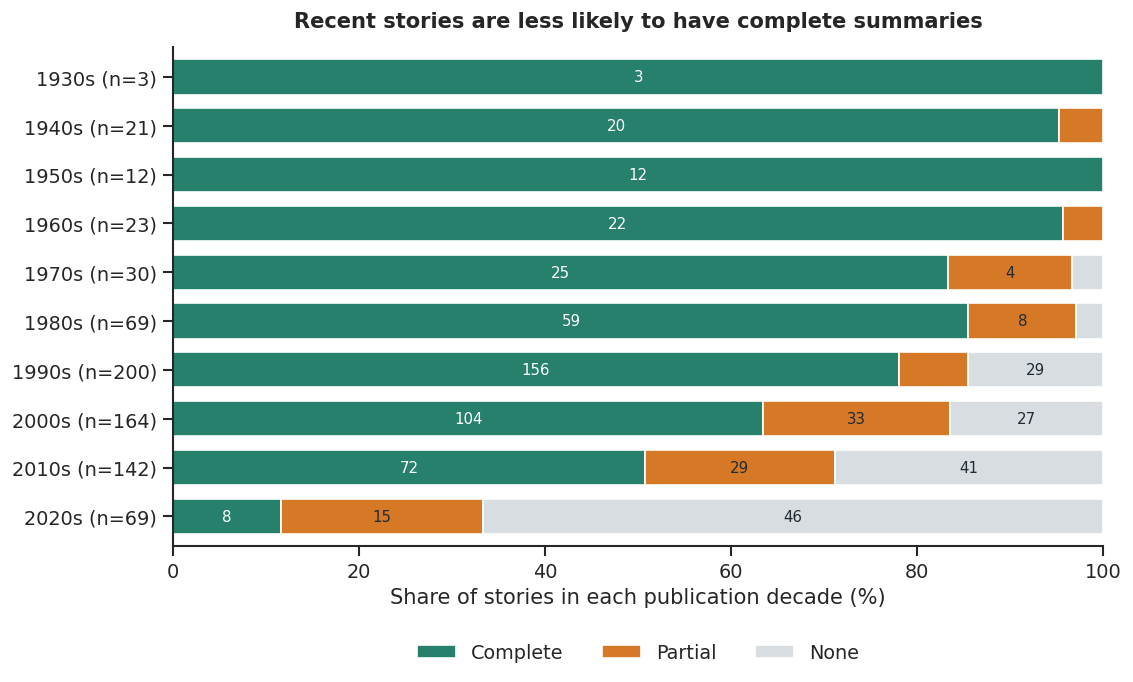

7 stories have no known decade and are not shown.


In [4]:
available = texts[texts.text_status.eq("available")].copy()
# Identical summaries (ignoring case and spacing) count once per story.
available["text_key"] = available.synopsis_text.str.casefold().str.split().str.join(" ")
plot_text = (
    available.drop_duplicates(["story_id", "text_key"])
    .groupby("story_id")
    .synopsis_text.agg("\n\n".join)
)
text_profile = stories[["story_id", "title", "rank", "cover_year_start"]].assign(
    plot_text=stories.story_id.map(plot_text).fillna(""),
    has_text=stories.story_id.isin(available.story_id),
    # Complete: every selected summary is available and the issue list is complete.
    complete=stories.story_id.map(texts.text_status.eq("available").groupby(texts.story_id).all())
    & stories.issue_list_complete,
)
text_profile["coverage"] = np.select(
    [text_profile.complete, text_profile.has_text], ["Complete", "Partial"], default="None"
)
text_profile["decade"] = (text_profile.cover_year_start // 10 * 10).astype("Int64")
coverage_order = ["Complete", "Partial", "None"]
text_by_era = pd.crosstab(text_profile.decade, text_profile.coverage)[coverage_order]
shares = 100 * text_by_era.div(text_by_era.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 5.4))
shares.plot.barh(
    stacked=True, color=[COLORS["green"], COLORS["orange"], "#D8DDE1"], width=0.72, ax=ax
)
for bars, status in zip(ax.containers, coverage_order):
    labels = [str(n) if share >= 9 else "" for n, share in zip(text_by_era[status], shares[status])]
    ax.bar_label(
        bars,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="white" if status == "Complete" else "#202B35",
    )
ax.set(
    yticklabels=[f"{decade}s (n={n})" for decade, n in text_by_era.sum(axis=1).items()],
    xlim=(0, 100),
    xlabel="Share of stories in each publication decade (%)",
    ylabel="",
    title="Recent stories are less likely to have complete summaries",
)
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
plt.show()
print(f"{text_profile.decade.isna().sum()} stories have no known decade and are not shown.")

### Vampires, nightmares and other ingredients

Nine fully summarized stories mention vampires, ranging from *Red Rain* (#6) to *Superman and Batman vs. Vampires and Werewolves* (#732). Five rank in the top 111; the other four are #568 or lower. The median alone hides that split.

These keyword matches include passing references; they are not reviewed theme labels. Each dot is a match among the 481 completely summarized stories; a story can appear in several rows. Longer summaries have more chances to match.

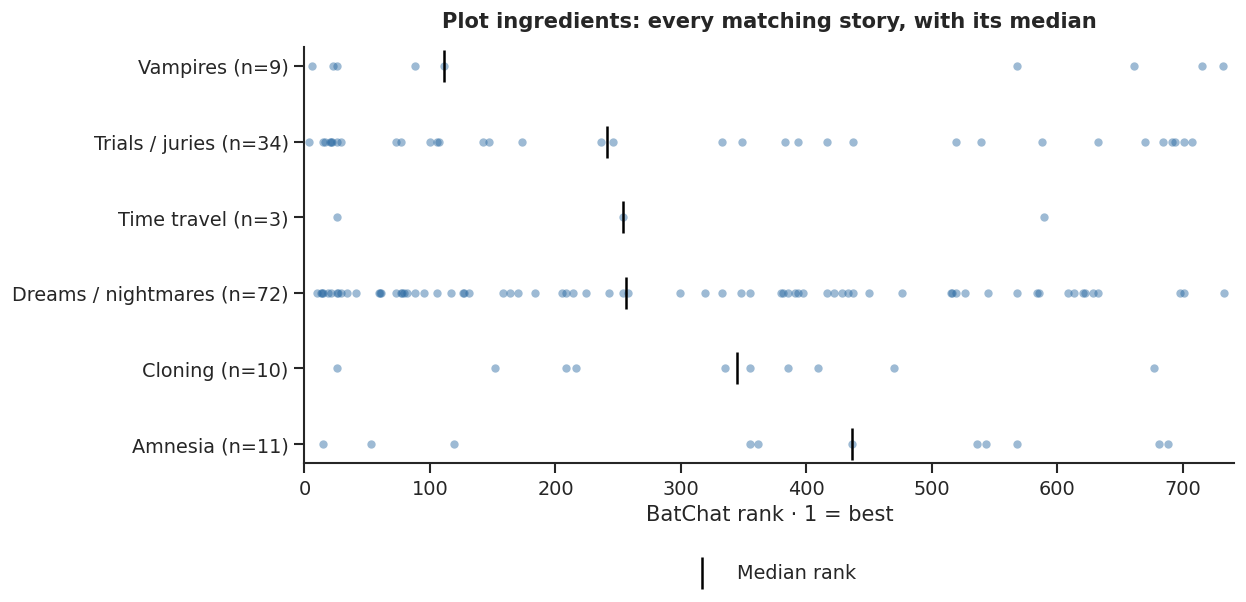

,Stories,Median rank,Best-ranked story,Worst-ranked story
topic,,,,
Vampires,9,111.0,Batman/Dracula: Red Rain OGN,Superman and Batman Vs. Vampires and Werewolves
Trials / juries,34,241.0,The Long Halloween,Identity Crisis
Time travel,3,254.0,Final Crisis,DCU Infinite Holiday Special #1
Dreams / nightmares,72,256.0,Batman: Black and White Vol.1,Mad
Cloning,10,345.0,Final Crisis,The Amazo Virus
Amnesia,11,436.0,Batman: R.I.P.,Superman’s Secret Kingdom


In [5]:
plot_terms = {
    "Vampires": r"\bvampir\w*",
    "Dreams / nightmares": r"\b(?:dreams?|nightmares?)\b",
    "Amnesia": r"\b(?:amnesia|amnesiac)\b",
    "Time travel": r"\btime[- ]trav\w*",
    "Trials / juries": r"\b(?:trial|jury|courtroom)\b",
    "Cloning": r"\bclon(?:e[sd]?|ing)\b",
}
complete_plots = text_profile[text_profile.complete].reset_index(drop=True)
term_matches = pd.concat(
    [
        complete_plots.loc[
            complete_plots.plot_text.str.contains(pattern, case=False),
            ["story_id", "title", "rank"],
        ].assign(topic=topic)
        for topic, pattern in plot_terms.items()
    ],
    ignore_index=True,
)
term_summary = rank_summary(term_matches, "topic").sort_values("median_rank")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(
    data=term_matches,
    x="rank",
    y="topic",
    order=term_summary.index,
    jitter=False,
    alpha=0.45,
    color=COLORS["blue"],
    ax=ax,
)
ax.scatter(
    term_summary.median_rank,
    range(len(term_summary)),
    marker="|",
    s=350,
    color="black",
    label="Median rank",
    zorder=4,
)
ax.set_yticks(range(len(term_summary)), [f"{k} (n={n})" for k, n in term_summary.n.items()])
ax.set(
    xlim=(0, N + 1),
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    title="Plot ingredients: every matching story, with its median",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()
term_summary.drop(columns=["best_rank", "worst_rank"]).rename(columns=PRETTY)

### Gotham without “Batman”

Larger words occur in more of the 481 completely summarized stories. Repetition within a story adds nothing. Common English words and selected character/place names are removed. Size encodes document frequency; rankings do not enter the cloud.

“Police” appears in **234** summaries, “death” in **203**, and “family” in **114**. The vocabulary mixes police work, mortality and personal ties. Generic narration verbs such as “takes” and “finds” are filtered out.

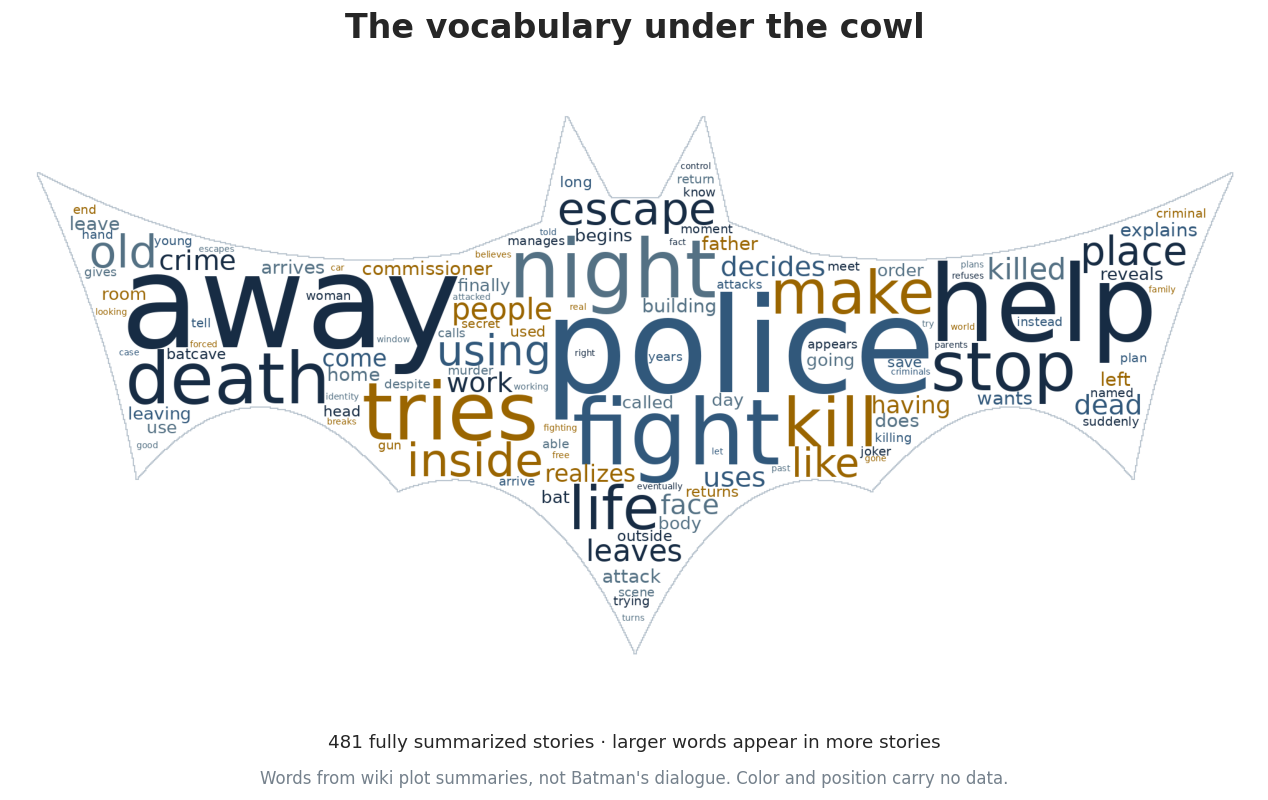

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.font_manager import findfont
from matplotlib.path import Path as ShapePath
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from wordcloud import WordCloud

extra_stopwords = set(
    """batman bruce wayne gotham city robin dick grayson tim drake
    jason todd alfred gordon riddler edward nashton nigma nygma penguin oswald cobblepot
    tells says asks comes goes gets just later soon new man men time way back
    takes taken taking makes made finds found sees seen knows
    couldn didn doesn isn wasn wouldn don ve ll aren weren hasn hadn haven shouldn needn mustn mightn won shan""".split()
)
vectorizer = CountVectorizer(
    binary=True,
    min_df=3,
    stop_words=sorted(ENGLISH_STOP_WORDS | extra_stopwords),
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
word_presence = vectorizer.fit_transform(complete_plots.plot_text)  # stories × words, 1 = present
terms = vectorizer.get_feature_names_out()
story_counts = pd.Series(word_presence.sum(axis=0).A1, index=terms)

# A drawn bat silhouette as the cloud mask; 0 = draw here.
bat_outline = ShapePath(
    [(20, 90), (190, 180), (360, 155), (425, 130), (445, 45), (480, 110), (520, 110), (555, 45),
     (575, 130), (640, 155), (810, 180), (980, 90), (920, 220), (900, 335), (800, 215), (690, 345),
     (580, 300), (500, 475), (420, 300), (310, 345), (200, 215), (100, 335), (80, 220), (20, 90), (20, 90)],
    [1, 3, 3, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 79],
)  # fmt: skip
yy, xx = np.mgrid[:520, :1000]
inside = bat_outline.contains_points(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
bat_mask = np.where(inside, 0, 255).astype("uint8")
font_path = findfont("DejaVu Sans")


def word_cloud(frequencies, mask, colors, max_words):
    return WordCloud(
        mask=mask,
        background_color="white",
        font_path=font_path,
        random_state=42,
        max_words=max_words,
        scale=2,
        prefer_horizontal=1,
        colormap=ListedColormap(colors),
        contour_width=1,
        contour_color="#BBC6D0",
    ).generate_from_frequencies(frequencies)


common_words = story_counts.sort_index().sort_values(ascending=False, kind="stable").head(120)
fig, ax = plt.subplots(figsize=(12, 6.8))
ax.imshow(
    word_cloud(common_words.to_dict(), bat_mask, ["#172C44", "#31587B", "#9A6500", "#547184"], 120)
)
ax.axis("off")
ax.set_title("The vocabulary under the cowl", fontsize=20, pad=14)
fig.text(
    0.5,
    0.10,
    f"{len(complete_plots)} fully summarized stories · larger words appear in more stories",
    ha="center",
    fontsize=11,
)
fig.text(
    0.5,
    0.055,
    "Words from wiki plot summaries, not Batman's dialogue. Color and position carry no data.",
    ha="center",
    fontsize=10,
    color=COLORS["grey"],
)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## Same length, different ways to tell a story

*Undone* uses **20 silent pages**. *The Clown at Midnight* uses **22 pages of illustrated prose**. They rank **47th and 85th**: similar lengths, very different reading experiences. [DC on the silent issue](https://www.dc.com/blog/2013/09/05/5-2-reasons-dc-comics-the-new-52-anniversary-edition)

A wiki summary can describe a silent image at length or squeeze pages of dialogue into a sentence. Its word count doesn't measure how wordy the comic is.

### What a plot summary can't show you

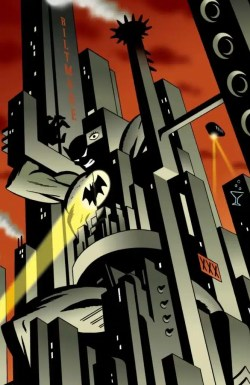

Batman almost disappears into the angular black shapes of Gotham. The orange sky separates the towers, and a yellow beam pulls the eye diagonally across the scene.

"Batman above Gotham" captures the subject but loses the composition.

Color also depends on the edition. Richmond Lewis colored *Year One* twice, for different presentations. Studying that difference would require knowing which version the hosts read. [DC on Richmond Lewis](https://www.dc.com/blog/2024/03/29/the-woman-whose-colors-brought-batman-year-one-to-life-twice)

*Darwyn Cooke artwork for Ego, © DC. Small image reproduced by [ComicsXF](https://comicsxf.com/batchat-rankings/); [image source](https://i0.wp.com/www.comicsxf.com/wp-content/uploads/2022/06/batman-ego-666x1024.webp?resize=640%2C984). Included for the visual commentary above.*

## Read the cloud as a summary

Text coverage leans old, summary length affects keyword matches, and a plot summary loses the page's composition. The cloud describes wiki prose. It does not measure how the comic reads.

Read next: [Character roles](https://www.kaggle.com/code/danofer/gotham-s-rogues-ranked) · [Prediction from summaries](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories)